# Classification Task

- Features = Images

 image -> np.array -> model -> index (0,1,2)

- 0 = DOG
- 1 = CAT
- 2 = PERSON

In [61]:
import torch
import os
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader


In [62]:
image_dir = '/kaggle/input/datasets/msp689/dog-cat-and-person-images-dataset/images/train'
for label, class_dir in enumerate(os.listdir(image_dir)):
     print(label,class_dir)

0 Cat
1 Dog
2 person


In [63]:
class ImageDataset(Dataset):
    def __init__ (self,image_dir,transform=None):
        self.image_dir = image_dir
        self.image_path = []
        self.labels = []
        self.class_name = {}
        self.transform = transform

        for label, class_dir in enumerate(os.listdir(image_dir)):
            self.class_name[label] = class_dir
            class_path = os.path.join(image_dir,class_dir)
            for img_name in os.listdir(class_path):
                self.image_path.append(os.path.join(class_path,img_name))
                self.labels.append(label)

    def __len__(self):
        return len(self.image_path)

    def __getitem__(self,idx):
        img_path = self.image_path[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image,label

In [64]:
transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor()]
)

In [65]:
train_image_dir = '/kaggle/input/datasets/msp689/dog-cat-and-person-images-dataset/images/train'
test_image_dir = '/kaggle/input/datasets/msp689/dog-cat-and-person-images-dataset/images/test'
train_image_dataset = ImageDataset(image_dir=train_image_dir,transform=transform)
test_image_dataset = ImageDataset(image_dir=test_image_dir,transform=transform)

In [66]:
train_loader = DataLoader(dataset=train_image_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(dataset=test_image_dataset,batch_size=32,shuffle=True)

In [67]:
import matplotlib.pyplot as plt
import numpy as np

print(train_image_dataset.class_name)
print(test_image_dataset.class_name)

{0: 'Cat', 1: 'Dog', 2: 'person'}
{0: 'Cat', 1: 'Dog', 2: 'person'}


torch.Size([32, 3, 128, 128]) torch.Size([32])
(3, 128, 128)
person
(128, 128, 3)
2


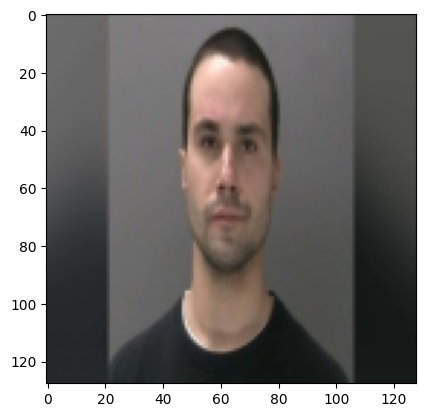

In [68]:
for images, labels in train_loader:
    print(images.shape,labels.shape)
    img = images[0].numpy()
    print(img.shape)
    label = labels[0].item()
    print(train_image_dataset.class_name[label])
    img = np.transpose(img,(1,2,0))
    print(img.shape)
    print(label)
    plt.imshow(img,vmin=0,vmax=255)
    break

# CNN

In [69]:
import torch.nn as nn
import torch.optim as optim

In [70]:
class CustomCnnModel(nn.Module):
    def __init__(self,input_dim, num_classes):
        super(CustomCnnModel,self).__init__()
        self.input_dim=input_dim
        self.num_classes=num_classes

        self.conv_layers=nn.Sequential(
            #C1
            nn.Conv2d(3,32,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),
    
            #C2
            nn.Conv2d(32,64,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),
    
            #C3
            nn.Conv2d(64,128,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),
    
            #C4
            nn.Conv2d(128,256,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2)
            
        )
    
        self._to_linear = None
        self._get_conv_output(self.input_dim)

        self.fc_layers=nn.Sequential(
            nn.Linear(self._to_linear,512),
            nn.ReLU(),
            nn.Linear(512,128),
            nn.ReLU(),
            nn.Linear(128,self.num_classes),
        )

    def _get_conv_output(self,input_dim=128):
        with torch.no_grad():
            dummy_input=torch.zeros(1,3,input_dim,input_dim)
            output=self.conv_layers(dummy_input)
            self._to_linear=output.view(1,-1).size(1)
            
    def forward(self,x):
        x = self.conv_layers(x)
        x = x.view(x.size(0),-1)
        x = self.fc_layers(x)
        return x
        

In [71]:
## Initalize Model
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = CustomCnnModel(input_dim=128,num_classes=3).to(device)



In [72]:
print(model)

CustomCnnModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_sta

In [73]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.001)

In [74]:
# Training Loop
epochs=40
for epoch in range(epochs):
    model.train()
    running_loss = 0.0 ## For each batch
    for images,labels in train_loader:
        images,labels=images.to(device),labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch: {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader)}")

Epoch: 1/40, Loss: 1.0065231938111154
Epoch: 2/40, Loss: 0.5887318909168243
Epoch: 3/40, Loss: 0.5308771214987102
Epoch: 4/40, Loss: 0.4647319277650432
Epoch: 5/40, Loss: 0.42913350462913513
Epoch: 6/40, Loss: 0.41957640757686215
Epoch: 7/40, Loss: 0.35660858460162814
Epoch: 8/40, Loss: 0.31579089321588216
Epoch: 9/40, Loss: 0.29315155234776047
Epoch: 10/40, Loss: 0.24157411761974035
Epoch: 11/40, Loss: 0.21579159047258528
Epoch: 12/40, Loss: 0.17764701703563332
Epoch: 13/40, Loss: 0.17923874866805578
Epoch: 14/40, Loss: 0.12879329615909801
Epoch: 15/40, Loss: 0.11461222786456346
Epoch: 16/40, Loss: 0.097420435967414
Epoch: 17/40, Loss: 0.13608139900392607
Epoch: 18/40, Loss: 0.07533697936389791
Epoch: 19/40, Loss: 0.04610288061330242
Epoch: 20/40, Loss: 0.039834179993914934
Epoch: 21/40, Loss: 0.04341884022823682
Epoch: 22/40, Loss: 0.03177869935140112
Epoch: 23/40, Loss: 0.07037635711266806
Epoch: 24/40, Loss: 0.034915158987707015
Epoch: 25/40, Loss: 0.031096574297407642
Epoch: 26/40

In [75]:
model.eval()
correct=0
total=0

with torch.no_grad():
    for images,labels in test_loader:
        images,labels=images.to(device),labels.to(device)
        outputs = model(images)
        _,predicted=torch.max(outputs,1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()


print(f"Test accuracy is: {100* correct / total:.2f}%")

Test accuracy is: 83.50%


In [76]:
torch.save(model.state_dict(),"cnn_model.pth")

In [77]:
import cv2

In [78]:
class ImageClassifier:
    def __init__(self,model_path,class_name):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model = CustomCnnModel(input_dim=128,num_classes=3).to(self.device)
        self.model.load_state_dict(torch.load(model_path,map_location=self.device))
        self.model.eval()
        self.class_name = class_name
        self.transform = transforms.Compose([
            transforms.Resize((128,128)),
            transforms.ToTensor()]
        )
    def predict(self,image_path):
        image=Image.open(image_path).convert("RGB")
        input_tensor=self.transform(image).unsqueeze(0).to(self.device)
        with torch.no_grad():
            outputs=self.model(input_tensor)
            _,predicted = torch.max(outputs,1)
        label = self.class_name[predicted.item()]

        img = cv2.imread(image_path)
        cv2.putText(img,label,(10,30),cv2.FONT_HERSHEY_SIMPLEX,1,(255,0,0),2)
        cv2.imwrite("output_image.jpg",img)
        return label

In [79]:
classifier=ImageClassifier("/kaggle/working/cnn_model.pth",train_image_dataset.class_name)
label = classifier.predict("/kaggle/input/datasets/msp689/dog-cat-and-person-images-dataset/images/test/Dog/dog_1000.jpg")

print(f"Predicted class is : {label}")

Predicted class is : Dog
